In [1]:
#importing relevant libraries
# import openai
import time
import os
import ta

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import style
import datetime as dt
from datetime import datetime, timedelta
import pandas_market_calendars as mcal

import ipywidgets as widgets
from ipywidgets import interactive
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

import plotly.graph_objects as go
import openpyxl
from openpyxl.drawing.image import Image
from openpyxl.workbook import Workbook
from openpyxl import load_workbook
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.utils import get_column_letter

import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
import plotly.express as px
import dash
from dash import dcc
from dash import html
from dash.dependencies import Input, Output
from IPython.display import clear_output
import xlsxwriter
import pytz
import json
from pytz import timezone
import re
import exchange_calendars as ecals
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import yfinance as yf
import itertools
import math
import bisect

import ipywidgets as widgets
from IPython.display import display
import dash
from dash import dcc, html, dash_table
import socket
hostname = socket.gethostname()
local_ip = socket.gethostbyname(hostname)

#ignoring the warnings
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 500)
# pd.set_option('display.max_colwidth', 1000)
SI_minfolder = rf"\\192.168.88.250\BigUSB\LAResearch\Interns\databento\Futures\ohlcv-1m\SI\\"
AG_minfolder = rf"\\192.168.89.201\rsfs\research\Refinitiv\Data\JQData\Futures\1m\XSGE\ag\\"
ranking_filepath = rf"\\192.168.88.250\BigUSB\LAResearch\Interns\jqdata\rank.csv"

min_folder = r'\\192.168.88.250\BigUSB\LAResearch\RavenPack\Output\Finnhub\min data\\'
df_mapping = pd.read_excel(r'\\192.168.88.250\BigUSB\LAResearch\Interns\TD\Mappings\product mapping.xlsx')
month_mapping = {"F": "01", "G": "02", "H": "03", "J": "04", "K": "05", "M": "06", "N": "07", "Q": "08", "U": "09", "V": "10", "X": "11", "Z": "12"}
output_folder = rf"\\192.168.88.250\BigUSB\LAResearch\Silver stocks strategy\Output\\"

# Functions

In [2]:
def modify_contract(contract):
    if len(contract) >= 2 and contract[-2:].isdigit():  # Check if last 2 characters are digits
        if int(contract[-2:]) < 30:
            return contract[:-2] + contract[-1]  # Remove the first digit from the last two
        else:
            return contract
    return contract

def get_previous_hourtime(dt, time_dict, time_list):
    idx = time_dict.get(dt, None)
    if idx is not None and idx > 0:
        return time_list[idx - 1]
    else:
        return pd.NaT  # or None if you pref


def convert_ticker(df_all, ticker, month_mapping):
    s = df_all[f"{ticker.upper()}_main"].astype(str)
    
    ticker_part = s.str[:-2]
    month_code  = s.str[-2].map(month_mapping)
    year_part   = (20 + s.str[-1].astype(int)).astype(str)
    
    df_all[f"{ticker.upper()}_main"] = ticker_part + year_part + month_code
    return df_all

In [3]:
def market_calendar():
    global df_calendar, Eightdays, Prevdate_cal
    Date_today =  datetime.today().strftime('%Y%m%d')
    # Create a trading calendar
    mktcal = mcal.get_calendar('NYSE')
    mkt_startdate = '20170101' #str(Twelvedays)[:4] + '-' + str(Twelvedays)[4:6] + '-' + str(Twelvedays)[6:]
    mkt_enddate = Date_today[:4] + '-' + Date_today[4:6] + '-' + Date_today[6:] #'2012-07-10' 
    #mkt_enddate = Eightydays_later[:4] + '-' + Eightydays_later[4:6] + '-' + Eightydays_later[6:] #'2012-07-10' 
    
    # No need to convert UTC to ET since it's 21:00 UTC datetime, which is always the same date as ET

    df_calendar= pd.DataFrame(mcal.date_range(mktcal.schedule(start_date= mkt_startdate , end_date= mkt_enddate), frequency='1D')).rename(columns = {0 : 'Datetime'})
    df_calendar['Date_cal'] = df_calendar['Datetime'].astype(str).str.slice(start = 0, stop = 10).str.replace('-','')
    df_calendar['Date_cal'] = df_calendar['Date_cal'].astype(int)
    df_calendar['Prevdate'] = df_calendar['Date_cal'].shift(1).fillna(0).astype(int)
    df_calendar['min_2days'] = df_calendar['Date_cal'].shift(2)
    df_calendar['min_3days'] = df_calendar['Date_cal'].shift(3)
    df_calendar['min_4days'] = df_calendar['Date_cal'].shift(4)
    df_calendar['min_5days'] = df_calendar['Date_cal'].shift(5)
    df_calendar['Next_date'] = df_calendar['Date_cal'].shift(-1).fillna(0).astype(int)
    df_calendar['5days'] = df_calendar['Date_cal'].shift(5)
    df_calendar['21days'] = df_calendar['Date_cal'].shift(21)
    df_calendar['63days'] = df_calendar['Date_cal'].shift(63)


    df_calendar.drop(columns = 'Datetime', inplace=True)
    #Prevdate_cal = df_calendar['Prevdate'].loc[df_calendar['Date_cal'] == int(Date_today)].item()
    df_calendar['Year'] = df_calendar['Date_cal'].astype(str).str.slice(start = 0, stop = 4).astype(int)
    df_calendar['Datetime'] = pd.to_datetime(df_calendar['Date_cal'].astype(str), format='%Y%m%d')
    df_calendar['Weeknumber'] = df_calendar['Datetime'].dt.isocalendar().week

In [4]:
def compute_30m_bucket(h, m):
    if h == 9:
        return 1  # 09:30-09:59
    else:
        # Number of 30-min blocks since 10:00
        return 2 + (h - 10) * 2 + (m // 30)

In [5]:
def onshore_ETL(df_concat, folder, key, error_dict):
    try:
        df_temp = pd.read_csv(rf"{folder}{key.split('-')[1]}\\{key.split('-')[0]}.CSV")
        df_temp['DT_ET'] = pd.to_datetime(df_temp['Unnamed: 0'])
        df_temp['DT_ET'] = df_temp['DT_ET'].dt.tz_localize('Asia/Shanghai')
        df_temp['DT_ET'] = df_temp['DT_ET'].dt.tz_convert('America/New_York').astype(str).str.replace('-05:00', '').str.replace('-04:00','')
        df_temp = df_temp[['DT_ET', 'open', 'close']].set_index('DT_ET')
        if not df_temp.empty:
            df_concat = pd.concat([df_concat, df_temp])
    except Exception as e:
        error_dict[key] = e
    return df_concat

In [6]:
def offshore_ETL(df_concat, folder, mc, td, error_dict):
    try:
        df_temp = pd.read_csv(rf"{folder}{mc}\\{mc}.CSV")
        df_temp['DT_ET'] = pd.to_datetime(df_temp['time_utc'])
        df_temp['DT_ET'] = df_temp['DT_ET'].dt.tz_convert('America/New_York').astype(str).str.replace('-05:00', '').str.replace('-04:00','')
        df_temp['Date_ET'] = df_temp['DT_ET'].astype(str).str.slice(stop=10).str.replace('-','').astype(int)
        df_temp = df_temp[df_temp['Date_ET'].isin(td)]
        df_temp = df_temp[['DT_ET', 'open', 'close']].set_index('DT_ET')
        if not df_temp.empty:
            df_concat = pd.concat([df_concat, df_temp])
    except Exception as e:
        error_dict[key] = e
    return df_concat

In [7]:
# Active table
def active_table():
    active_folder = r'\\192.168.88.250\BigUSB\LAResearch\Interns\Active table\\'
    df_active = pd.read_csv(active_folder + [x for x in os.listdir(active_folder) if '.csv' in x.lower()][-1])
    df_active["Startdate"] = pd.to_datetime(df_active["StDate"], format="%Y-%m-%d").dt.strftime("%Y%m%d").astype(int) # "%m/%d/%Y"
    df_active["Enddate"] = pd.to_datetime(df_active["EdDate"], format="%Y-%m-%d").dt.strftime("%Y%m%d").astype(int)
    df_active.rename(columns = {'ActiveContract':'Contract'}, inplace=True)
    df_active.drop(columns = ['StDate', 'EdDate'], inplace=True)
    df_active = df_active[df_active['Startdate'] >= 20210101].sort_values(by=['Product','Startdate']).reset_index(drop=True)
    df_active['Product'] = df_active['Product'].str.lower().str.rstrip() 
    df_active = df_active.merge(df_mapping[['ChainRIC']].set_index(df_mapping['BloombergCode'].str.lower()), left_on = 'Product', right_index=True, how = 'left')
    df_active['RIC Root'] = df_active['ChainRIC'].str.replace('0#','').str.replace(':','')
    df_active['RIC'] = df_active['Contract'].loc[df_active['RIC Root'].notna()].apply(modify_contract)
    df_active['RIC'] = df_active.apply(lambda row: str(row['RIC']).replace(row['Product'].upper(), row['RIC Root']) if isinstance(row['RIC'], str) else row['RIC'], axis=1)
    df_active['Key'] = df_active['Startdate'].astype(str) + df_active['RIC']
    df_rollover_sd = df_active[['Key']].set_index('Key')
    df_rollover_sd['ind_rollover'] = 1
    return df_active

In [8]:
def load_XAG():
    df_XAG = pd.read_csv(rf"\\192.168.88.250\BigUSB\LAResearch\Interns\CCXT\Binance\Minutes\XAG_consolidated\XAG_2026.csv")
    df_XAG['DT ET_str'] = (pd.to_datetime(df_XAG['datetime'], utc=True).dt.tz_convert('US/Eastern')).astype(str).str.slice(stop=-6)
    df_XAG = df_XAG.sort_values(by='datetime')
    df_XAG['XAG_log_old'] = np.log(df_XAG['close']).diff()
    df_XAG['XAG_pct_old'] = df_XAG['close'].pct_change()
    
    # 1️⃣ Convert datetime to US/Eastern and create string index
    df_XAG['DT ET'] = (
        pd.to_datetime(df_XAG['datetime'], utc=True)
          .dt.tz_convert('US/Eastern')
    )
    
    # 2️⃣ Sort by datetime (important!)
    df_XAG = df_XAG.sort_values('datetime').reset_index(drop=True)
    
    # 3️⃣ Compute minute gaps to identify valid adjacent rows
    s = df_XAG['DT ET'].diff().dt.total_seconds()
    valid = s.between(50, 70)      # only 1-minute gaps are allowed
    safe = valid & valid.shift()     # both t and t-1 must be valid
    
    # 4️⃣ Compute safe log and pct returns
    df_XAG.loc[safe, 'XAG_log'] = np.log(df_XAG['close']) - np.log(df_XAG['close'].shift())
    df_XAG.loc[safe, 'XAG_pct'] = df_XAG['close'] / df_XAG['close'].shift() - 1
    df_XAG.rename(columns = {'close':'XAG_close'}, inplace=True)
    return df_XAG

# Data preparation

In [30]:
startdate = 20250101
enddate = int(str(datetime.now() - timedelta(days = 3))[:10].replace('-',''))
ticker_list = ['HL', 'AG-US', 'PAAS', 'CDE', 'WPM', 'FSM', 'EXK', 'ASM', 'SLV']
ind_include_cn = 0

In [31]:
# Check minutes files for the tickers
try:
    file_list_og[0]
except:
    file_list_og = os.listdir(min_folder)
file_list = [x for x in file_list_og if (int(x[:8]) >= startdate) and (int(x[:8]) <= enddate)]

for ticker in ticker_list + ['SLV']:
    ticker = ticker.replace('-US','')
    ticker_files = [x.split(ticker)[0] for x in file_list if (f"{ticker}.CSV" in x) and (len(x[8:].upper().replace('.CSV','')) == len(ticker))]
    print(f"{ticker} minutes file \tcount: {len(ticker_files)} \tmin: {min(ticker_files)} \tmax: {max(ticker_files)}")

HL minutes file 	count: 267 	min: 20250102 	max: 20260305
AG minutes file 	count: 266 	min: 20250102 	max: 20260512
PAAS minutes file 	count: 362 	min: 20250102 	max: 20260612
CDE minutes file 	count: 266 	min: 20250102 	max: 20260514
WPM minutes file 	count: 269 	min: 20250102 	max: 20260508
FSM minutes file 	count: 267 	min: 20250102 	max: 20260518
EXK minutes file 	count: 265 	min: 20250102 	max: 20260123
ASM minutes file 	count: 266 	min: 20250102 	max: 20260406
SLV minutes file 	count: 362 	min: 20250102 	max: 20260612
SLV minutes file 	count: 362 	min: 20250102 	max: 20260612


In [32]:
# Main code
market_calendar()

if ind_include_cn == 1:
    df_ranking = pd.read_csv(ranking_filepath)[['Date','AG_main','SI_main']]
    # df_ranking.columns = [x.split('_')[0] for x in df_ranking.columns]
    df_active_og = active_table()

# 1️⃣ Generate all calendar days between startdate and enddate
all_days = pd.date_range(start=str(startdate), end=str(enddate), freq='B')
df_all = pd.DataFrame({'Trading date': all_days})
df_all['Trading date'] = df_all['Trading date'].dt.strftime('%Y%m%d').astype(int)

# 2️⃣ Generate 24/7 minute times
times_24h = pd.date_range("00:00", "23:59", freq="T").time  # 1-min intervals
times_24h = list(times_24h)  # <-- convert to list so we can multiply

# 3️⃣ Repeat each date for all minutes
df_all_expanded = df_all.loc[df_all.index.repeat(len(times_24h))].copy()
df_all_expanded['time'] = times_24h * len(df_all)  # now works

# 4️⃣ Combine date + time into datetime column
df_all_expanded['DT'] = pd.to_datetime(
    df_all_expanded['Trading date'].astype(str) + ' ' + df_all_expanded['time'].astype(str),
    format='%Y%m%d %H:%M:%S'
)

# 5️⃣ Optional: drop temporary 'time' column
df_all_expanded = df_all_expanded.drop(columns='time').reset_index(drop=True)

# 6️⃣ Flag NYSE RTH (from df_calendar)
nyse_days = df_calendar['Date_cal'].astype(int).tolist()
df_all_expanded['ind_nyse_rth'] = (
    df_all_expanded['Trading date'].isin(nyse_days) &
    df_all_expanded['DT'].dt.hour.between(9, 15) &  # 09:00-15:59
    ((df_all_expanded['DT'].dt.hour != 9) | (df_all_expanded['DT'].dt.minute >= 30))  # start 09:30
)

df_all = df_all_expanded

# Vectorized 30-min bucket within RTH
# 09:30 = bucket 0, 10:00 = bucket 1, ..., 15:30 = bucket 13
hour = df_all['DT'].dt.hour
minute = df_all['DT'].dt.minute
df_all['ind_30m'] = pd.NA
mask_rth = df_all['ind_nyse_rth']
df_all.loc[mask_rth, 'ind_30m'] = ((hour[mask_rth] * 60 + minute[mask_rth]) - 570) // 30 + 1


# Add xshg indicator
et = pytz.timezone('US/Eastern')
cst = pytz.timezone('Asia/Shanghai')
df_all['DT_cst'] = df_all['DT'].dt.tz_localize(et).dt.tz_convert(cst)
hour_cst = df_all['DT_cst'].dt.hour
minute_cst = df_all['DT_cst'].dt.minute
df_all['ind_xshg_rth'] = (
    ((hour_cst == 9) & (minute_cst >= 30) | (hour_cst == 10) | (hour_cst == 11)) |  # morning 09:30-11:30
    ((hour_cst == 13) | (hour_cst == 14) | ((hour_cst == 15) & (minute_cst == 0)))  # afternoon 13:00-15:00
)


# df_all = df_all.merge(df_ranking.set_index('Date'), left_on = 'Trading date', right_index=True, how='left')
df_all = df_all.sort_values('Trading date')

if ind_include_cn == 1:
    for ticker in ['AG','SI']:
        df_active = df_active_og[df_active_og['Product'] == ticker.replace('AG', 'SAI').lower()][['Contract', 'Startdate', 'Enddate']].copy().rename(columns={'Contract':f"{ticker.upper()}_main"})
        df_active = df_active.sort_values('Startdate')
        df_active[f"{ticker.upper()}_main"] = df_active[f"{ticker.upper()}_main"].str.replace('SAI', 'AG').str.replace('sai', 'AG')
        df_all = pd.merge_asof(df_all,df_active[['Startdate', 'Enddate', f"{ticker.upper()}_main"]],left_on='Trading date',right_on='Startdate',direction='backward')
        df_all[f"{ticker.upper()}_main"] = df_all[f"{ticker.upper()}_main"].where(df_all['Trading date'] <= df_all['Enddate'])
        df_all[f"{ticker.upper()}_main"] = df_all[f"{ticker.upper()}_main"].str.replace('^2', '').apply(modify_contract)
        df_all.drop(columns = ['Startdate', 'Enddate'], inplace=True)
        df_all = convert_ticker(df_all, ticker, month_mapping)


    for col in ['AG_main', 'SI_main']:
        df_all[col] = df_all[col].ffill()

df_all['Date_str'] = df_all['DT'].astype(str)
df_all_copy = df_all.copy()

error_dict ={}

if ind_include_cn == 1:
    product_dict = {'AG': AG_minfolder, 'SI':SI_minfolder}
else:
    product_dict = {}
for ticker in ticker_list:
    if ticker == 'AG':
        product_dict['AG-US'] = min_folder
    else:
        product_dict[ticker] = min_folder

df_all = df_all.sort_values(by='DT')
for ticker, folder in product_dict.items(): 
    # folder = globals()[f"{ticker}_minfolder"]
    df_concat = pd.DataFrame()
    if ticker == 'AG': 
        for key in (df_all['Trading date'].astype(str) + '-' + df_all[f"{ticker}_main"]).unique():
            df_concat = onshore_ETL(df_concat, folder, key, error_dict)
            df_AG = df_concat.copy()
    elif ticker == 'SI':
        for mc in df_all[f"{ticker}_main"].unique():
            td_list = df_all[df_all[f"{ticker}_main"] == mc]['Trading date'].unique().tolist()
            df_concat = offshore_ETL(df_concat, folder, mc, td_list, error_dict) # Need to trim dates
            df_SI = df_concat.copy()
    elif 'finn' in folder.lower():
        for key in (df_all['Trading date'].astype(str) + ticker).unique():
            try:
                df_temp = pd.read_csv(rf"{min_folder}\\{key.replace('-US','')}.csv")
                if not df_temp.empty:
                    # df_temp['Date_str'] = df_temp['Time ET Rounded'].str.replace('-','')
                    df_temp.rename(columns = {'Close':'close', 'Open':'open'}, inplace=True)
                    df_temp = df_temp[['Time ET Rounded', 'open', 'close']].set_index('Time ET Rounded')
                    df_concat = pd.concat([df_concat, df_temp])
            except Exception as e:
                error_dict[key] = e
    # if ticker in ['AG','SI']:
    #     globals()[f"df_{ticker}"] = df_concat.sort_index().reset_index().copy()
    #     if 'open' in df_concat:
    #         df_concat.drop(columns = ['open'], inplace=True)
    df_concat.sort_index(inplace=True)
    df_concat.rename(columns = {'close':ticker, 'open': f"{ticker}_open"}, inplace=True)
    df_all = df_all.merge(df_concat, left_on = 'Date_str', right_index=True,  how='left')
    df_all = df_all.sort_values(by='DT')

    valid = df_all['DT'].diff().dt.total_seconds().between(50, 70)
    safe = valid & valid.shift()
    df_all.loc[safe, f"{ticker}_pct"] = df_all[ticker] / df_all[ticker].shift() - 1
    df_all.loc[safe, f"{ticker}_log"] = np.log(df_all[ticker]) - np.log(df_all[ticker].shift())
    
    df_all[f"{ticker}_pct_test"] = df_all[f"{ticker}"].pct_change()
    df_all[f"{ticker}_log_test"] =  np.log(df_all[f"{ticker}"]).diff()

# df_all['SI_close_shifted'] = df_all['SI'].shift()
# for prod in ['AG', 'SI']:
#     df_all[f"{prod}_close_shifted"] = df_all[f"{prod}"].shift(-1)
#     df_all[f"{prod}_log_shifted"] = np.log(df_all[f"{prod}_close_shifted"]).diff()
#     df_all[f"{prod}_pct_shifted"] = df_all[f"{prod}_close_shifted"].pct_change()
s = df_all['DT'].diff().dt.total_seconds()
valid = s.between(50, 70)
safe = valid & valid.shift()

if ind_include_cn == 1:
    df_all.loc[safe, 'AG_log_shifted'] = np.log(df_all['AG'].shift(-1)) - np.log(df_all['AG'])
    df_all.loc[safe, 'AG_pct_shifted'] = df_all['AG'].shift(-1) / df_all['AG'] - 1

# df_XAG = load_XAG()
# df_all = df_all.merge(df_XAG[['DT ET_str', 'XAG_log', 'XAG_close', 'XAG_pct']].set_index('DT ET_str'), left_on = 'Date_str', right_index=True, how='left')
df_all_copy2 = df_all.copy()
print(f"Done")

Done


# Correlation US stocks (NYSE RTH)

In [ ]:
# Correlation
method = 'pct' # pct or log
df_test = df_all_copy2.copy()
df_test = df_test[(df_test['ind_nyse_rth'] == True) & (df_test['Trading date'].between(20251101, 20260201))]
ticker_cols = [f"{t}_{method}" for t in ticker_list]  + [f"XAG_{method}"]
products = [f"AG_{method}_shifted",  f"SI_{method}"] # , f"AG_{method}"

# Compute correlation matrix
corr_matrix = df_test[ticker_cols + products].corr()

# Extract only correlations between tickers and AG/SI
corr_df = corr_matrix.loc[ticker_cols, products]
corr_df.index = ticker_list + ['XAG']

for prod in products:
    globals()[f"df_corr_{prod.replace(f'_{method}','')}"] = corr_df[[prod]].copy()

    for i in sorted(df_test['ind_30m'].unique()):
        df_corr_temp = df_test[df_test['ind_30m'] == i][ticker_cols + [prod]].corr()
        df_corr_temp = df_corr_temp.loc[ticker_cols, [prod]]
        df_corr_temp.index = ticker_list + ['XAG']
        df_corr_temp.rename(columns={prod: f"{prod}_{i}"}, inplace=True)

        globals()[f"df_corr_{prod.replace(f'_{method}','')}"] = (
            globals()[f"df_corr_{prod.replace(f'_{method}','')}"]
            .merge(df_corr_temp, left_index=True, right_index=True, how='left')
        )

    cols = [f"{prod}_{i}" for i in range(2, 7)]
    base = prod.replace(f'_{method}', '')

    globals()[f"df_corr_{base}"][f"{base}_mean_2_to_6"] = (
        globals()[f"df_corr_{base}"][cols].mean(axis=1)
    )

    globals()[f"df_corr_{base}"] = globals()[f"df_corr_{base}"].dropna(axis=1, how='all')
    display(globals()[f"df_corr_{base}"])

In [ ]:
# Correlation with counts
for prod in products:
    base_name = prod.replace(f"_{method}", '')

    # --- overall correlation ---
    corr_df_prod = corr_df[[prod]].copy()

    # overall count
    cnt_series = pd.Series(
        {
            t: df_test[[f"{t}_{method}", prod]].dropna().shape[0]
            for t in ticker_list + ['XAG']
        },
        name=f"{prod}_count"
    )
    corr_df_prod = corr_df_prod.join(cnt_series)

    globals()[f"df_corr_{base_name}"] = corr_df_prod

    # --- per ind_30m ---
    for i in sorted(df_test['ind_30m'].unique()):
        df_sub = df_test[df_test['ind_30m'] == i]

        # correlations
        df_corr_temp = df_sub[ticker_cols + [prod]].corr()
        df_corr_temp = df_corr_temp.loc[ticker_cols, [prod]]
        df_corr_temp.index = ticker_list + ['XAG']
        df_corr_temp.rename(columns={prod: f"{prod}_{i}"}, inplace=True)

        # counts
        df_cnt_temp = pd.DataFrame(
            {
                f"{prod}_count_{i}": [
                    df_sub[[col, prod]].dropna().shape[0]
                    for col in ticker_cols
                ]
            },
            index=ticker_list + ['XAG']
        )

        # merge both
        globals()[f"df_corr_{base_name}"] = (
            globals()[f"df_corr_{base_name}"]
            .merge(df_corr_temp, left_index=True, right_index=True, how='left')
            .merge(df_cnt_temp, left_index=True, right_index=True, how='left')
        )

    # --- mean correlation (2 to 6) ---
    corr_cols = [f"{prod}_{i}" for i in range(2, 7)]
    globals()[f"df_corr_{base_name}"][f"{base_name}_mean_2_to_6"] = (
        globals()[f"df_corr_{base_name}"][corr_cols].mean(axis=1)
    )

    # --- drop empty columns ---
    globals()[f"df_corr_{base_name}"] = (
        globals()[f"df_corr_{base_name}"].dropna(axis=1, how='all')
    )
    display(globals()[f"df_corr_{base_name}"])


# Other tests

In [ ]:
products = ['XAG', 'AG', 'SI']
methods = ['pct', 'log']
td_range =  [20260101, 20260201]
period = '' # '', 'NYSE' , 'XSHG'

df_all = df_all_copy2.copy() # 'ind_nyse_rth' , 'ind_xshg_rth'

if period == 'NYSE':
    df_all = df_all[df_all['ind_nyse_rth'] == True]
elif period == 'XHSG':
    df_all = df_all[df_all['ind_xshg_rth'] == True]

if len(td_range) == 2:
    td_range = sorted(td_range)
    df_all = df_all.loc[df_all['Trading date'].between(td_range[0], td_range[1], inclusive='both')]
    print(f"Correlations for dates {df_all['Trading date'].min()}-{df_all['Trading date'].max()}")
for method in methods:
    print(f"\n=== {method.upper()} correlations ===")
    for p1, p2 in itertools.combinations(products, 2):
        s1 = df_all[f"{p1}_{method}"]
        s2 = df_all[f"{p2}_{method}"]

        if 'AG' in (p1, p2):
            s1 = s1.shift(-1) if p1 == 'AG' else s1
            s2 = s2.shift(-1) if p2 == 'AG' else s2

        corr = s1.corr(s2)
        print(f"{p1} vs {p2}: {corr:.5f}")

In [ ]:
df_test = df_all_copy2.copy()
df_test = df_test[df_test['Trading date']> 20260101]

print(f"Date range: {df_test['Trading date'].min()}-{df_test['Trading date'].max()}")
print(f"Correlation using log. Original: {round(df_test['AG_log'].corr(df_test['SI_log']),3)}. Shifted: {round(df_test['AG_log_shifted'].corr(df_test['SI_log']),5)}")
print(f"Correlation using pct. Original: {round(df_test['AG_pct'].corr(df_test['SI_pct']),3)}. Shifted: {round(df_test['AG_pct_shifted'].corr(df_test['SI_pct']),5)}")

In [ ]:
# Checking correlation with all datapoints for df_XAG
df_correlation = df_XAG.copy()
s = pd.to_datetime(df_correlation['DT ET'])
df_correlation['ind_nyse_rth'] = ((s.dt.weekday < 5) &((s.dt.hour > 9) |((s.dt.hour == 9) & (s.dt.minute >= 30))) &(s.dt.hour < 16)).astype(int)
# df_correlation = df_correlation[df_correlation['ind_nyse_rth'] == 1]

method = 'log'
print(f"Correlation test using XAG file using {method}")

for prod in ['AG', 'SI']:
    df_correlation = df_correlation.merge(globals()[f"df_{prod}"].rename(columns = {'close':f"{prod}_close", 'open':f"{prod}_open"}), left_on = 'DT ET', right_index=True, how='left')
    df_correlation[f"{prod}_{method}"] = np.log(df_correlation[f"{prod}_close"]).diff()
    if prod == 'AG':
        df_correlation[f"{prod}_{method}"] = df_correlation[f"{prod}_{method}"].shift(-1)
    count = df_correlation.loc[(df_correlation[f"{prod}_{method}"].notna()) & (df_correlation[f"XAG_{method}"].notna())].shape[0]
    crr = round(df_correlation[f"{prod}_{method}"].corr(df_correlation[f"XAG_{method}"]),4)
    
    df_temp_0 = df_correlation[df_correlation['ind_nyse_rth'] == 0].copy()
    count_0 = df_temp_0.loc[(df_temp_0[f"{prod}_{method}"].notna()) & (df_temp_0[f"XAG_{method}"].notna())].shape[0]
    crr_0 = round(df_temp_0[f"{prod}_{method}"].corr(df_temp_0[f"XAG_{method}"]),4)

    df_temp_1 = df_correlation[df_correlation['ind_nyse_rth'] == 1].copy()
    count_1 = df_temp_1.loc[(df_temp_1[f"{prod}_{method}"].notna()) & (df_temp_1[f"XAG_{method}"].notna())].shape[0]
    crr_1 = round(df_temp_1[f"{prod}_{method}"].corr(df_temp_1[f"XAG_{method}"]),4)
    mindate = df_correlation['Trading date_utc'].min()
    maxdate = df_correlation['Trading date_utc'].max()
    print(f"{mindate}-{maxdate} | Correlation between XAG and {prod}: {crr} (count: {count}). During NYSE rth: {crr_1} ({count_1}). Outside rth: {crr_0} ({count_0})")

In [ ]:
# Checking if there is lag in correlation
df_test = df_all_copy2.copy()
# df_test = df_test[df_test['Trading date'].between(20260101, 20260120)]
print(f"{df_test['Trading date'].min()}-{df_test['Trading date'].max()}")
r_lag = df_test['PAAS_log']
r_lead = df_test['SI_log']
for k in range(0, 16):
    corr = r_lag.shift(-k).corr(r_lead)
    print(f"correlation for shift -{k}: {corr}")
    

In [ ]:
df_test = df_all_copy2.copy()
for td in df_test['Trading date'].unique():
    df_temp = pd.DataFrame()
    df_temp = df_all_copy2[df_all_copy2['Trading date'] == td].copy()
    corr_reg = round(df_temp['AG_log'].corr(df_temp['SI_log']), 2)
    corr_shift = round(df_temp['AG_log_shifted'].corr(df_temp['SI_log']), 2)
    corr_test = round(df_temp['AG_log'].corr(df_temp['SI_log_shifted']), 2)
    wd = datetime.strptime(str(td), "%Y%m%d").strftime("%A")
    print(f"{td} {wd} | regular: {corr_reg}, shifted: {corr_shift}")

In [ ]:
# Testing using raw data
try:
    df_test_combined.shape
except:
    df_test_SI = pd.read_csv(rf"\\192.168.88.250\BigUSB\LAResearch\Interns\databento\Futures\ohlcv-1m\SI\SI2603\SI2603.csv")
    df_test_SI['time_hk'] = pd.to_datetime(df_test_SI['time_utc']).dt.tz_convert('Asia/Hong_Kong').astype(str).str.split('+').str[0]
    df_test_SI.rename(columns = {'close':'SI_close'}, inplace=True)
    df_test_SI = df_test_SI.sort_values(by='time_utc')
    df_test_SI['SI_pct'] = df_test_SI['SI_close'].pct_change()
    df_test_SI['SI_log'] = np.log(df_test_SI['SI_close']).diff()
    jq_silver_folder = rf"\\192.168.89.201\rsfs\research\Refinitiv\Data\JQData\Futures\1m\XSGE\ag\ag2603\\"
    df_test_AG = pd.DataFrame()
    for file in os.listdir(jq_silver_folder):
        df_temp = pd.read_csv(jq_silver_folder + file)
        df_test_AG = pd.concat([df_test_AG , df_temp])
    
    df_test_AG.rename(columns = {'Unnamed: 0':'Datetime HK', 'close':'AG_close'}, inplace=True)
    df_test_AG = df_test_AG.sort_values(by='Datetime HK')
    df_test_AG['AG_close'] = df_test_AG['AG_close'] # .shift(-1)
    df_test_AG['AG_pct'] = df_test_AG['AG_close'].pct_change()
    df_test_AG['AG_log'] = np.log(df_test_AG['AG_close']).diff()
    df_test_combined = df_test_AG.merge(df_test_SI[['time_hk','SI_close', 'SI_pct', 'SI_log']].set_index('time_hk'), left_on = 'Datetime HK', right_index=True, how='left')
    df_test_combined['Date'] = df_test_combined['Datetime HK'].str.split(' ').str[0].str.replace('-','').astype(int)



products = ['AG', 'SI']
methods = ['pct', 'log']
td_range =  [20260101, 20260201]

df_all = df_test_combined.copy()

if len(td_range) == 2:
    td_range = sorted(td_range)
    df_all = df_all.loc[df_all['Date'].between(td_range[0], td_range[1], inclusive='both')]
    print(f"Correlations for dates {df_all['Date'].min()}-{df_all['Date'].max()}")
for method in methods:
    print(f"\n=== {method.upper()} correlations ===")
    for p1, p2 in itertools.combinations(products, 2):
        s1 = df_all[f"{p1}_{method}"]
        s2 = df_all[f"{p2}_{method}"]

        if 'AG' in (p1, p2):
            s1 = s1.shift(-1) if p1 == 'AG' else s1
            s2 = s2.shift(-1) if p2 == 'AG' else s2

        corr = s1.corr(s2)
        print(f"{p1} vs {p2}: {corr:.4f}")

# Crypto strat on silver

In [33]:
def get_dynamic_value(row, ticker_col, template, ret_col=None):
    """
    row:          DataFrame row
    ticker_col:   column that contains the ticker name
    template:     string template, e.g. '{ticker}_{ret_col}'
    ret_col:        dynamic suffix, e.g. 'Gapret'
    """
    ticker = row[ticker_col]
    col = template.format(ticker=ticker, ret_col=ret_col)
    return row[col] if col in row.index else float('nan')


In [34]:
# add prev_r_vola_60!!!!!!
market_calendar()
for ticker in ticker_list :
    df, globals()[f"df_{ticker}"] = pd.DataFrame(), pd.DataFrame()
    try:
        ticker_original = ticker
        ticker = ticker.replace('-US','')
        df = yf.download(ticker.replace('-US',''),start="2020-09-01",end=datetime.today().strftime('%Y-%m-%d'),interval="1d")
        df.columns = ['{}_{}'.format(col[1], col[0]) for col in df.columns]
        df.reset_index(inplace=True)
        df['Trading date'] = df['Date'].astype(str).str.replace('-','').astype(int)
        df = df.merge(df_calendar[['Date_cal', 'Prevdate']].set_index('Date_cal'), left_on = 'Trading date', right_index=True, how='left')
        df = df.merge(df[['Trading date', f"{ticker}_Open", f"{ticker}_Close"]].set_index('Trading date').add_prefix('Prev'),left_on = 'Prevdate', right_index=True, how='left')
        df.rename(columns = {f"Prev{ticker}_Close": f"{ticker}_PrevClose", f"Prev{ticker}_Open": f"{ticker}_PrevOpen"}, inplace=True)
        df[f"{ticker}_Prevret"] = df[f"{ticker}_PrevClose"] / df[f"{ticker}_PrevOpen"] -1
        df[f"{ticker}_Gapret"] = df[f"{ticker}_Open"] / df[f"{ticker}_PrevClose"] -1
        df[f"{ticker}_coc"] = df[f"{ticker}_Close"] / df[f"{ticker}_PrevClose"] -1
        # df = df.applymap(lambda x: float(f"{x:.10f}") if isinstance(x, float) else x)
        # df[f"{ticker}_Gapret"] = df[f"{ticker}_Gapret"].apply(lambda x: f"{x:.5f}")

        df['Log_ret'] = np.log(df[f"{ticker}_Close"]/df[f"{ticker}_Close"].shift(1)) # df[f"{ticker}_PrevClose"])
        df['RtRt'] = df['Log_ret'] * df['Log_ret']
        df['Rtsum'] = (df['RtRt'].rolling(60).sum()).astype(float)
        df['rVola_60'] = np.sqrt(252 / 60 * df['Rtsum']) 
        df = df.merge(df[['Trading date', 'rVola_60']].set_index('Trading date').add_prefix(f'{ticker}_'),left_on = 'Prevdate', right_index=True, how='left')
        df.columns = [x.replace(ticker, ticker_original) for x in df.columns]
        ticker = ticker_original
        globals()[f"df_{ticker}"] = df.copy()
    except Exception as e:
        print(f"{ticker}: {e}")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [35]:
# Important!
df_data = df_all_copy2.copy()
df_data = df_data[[x for x in df_data.columns if 'log' not in x]]
df_data['Time'] = df_data['Date_str'].str.split(' ').str[1].str.replace(':00','')
df_data_copy = df_data.copy() 

In [ ]:

if ind_include_cn == 1:
    df_pc = df_data[(df_data['Date_str'].str.slice(start = -8).isin(['09:30:00','15:56:00', '15:57:00', '15:58:00', '15:59:00'])) & (df_data['ind_nyse_rth'] == True)].copy()
    df_pc.loc[df_pc['Date_str'].str.slice(start = -8) == '09:30:00' ,'ind_openclose'] = 1
    df_pc.loc[df_pc['Date_str'].str.slice(start = -8) == '15:59:00' ,'ind_openclose'] = 0
    
    df_pcsi = df_pc[['Trading date']].drop_duplicates().reset_index(drop=True).sort_values(by='Trading date')
    df_pcsi = df_pcsi.merge(df_calendar[['Date_cal','Prevdate']].set_index('Date_cal'), left_on='Trading date', right_index=True, how='left')
    for index, row in df_pcsi.iterrows():
        df_pcsi.loc[index, "SI_open"] = df_pc.loc[(df_pc['Trading date'] == row['Trading date']) & (df_pc['ind_openclose'] == 1)]["SI_open"].iloc[0]
        close_price = df_pc.loc[(df_pc['Trading date'] == row['Trading date']) & (df_pc['ind_openclose'] == 0)]["SI"].iloc[0]
        if close_price == None or pd.isna(close_price):
            try:
                close_price = df_pc.loc[(df_pc['Trading date'] == row['Trading date']) & (df_pc['ind_openclose'] != 1) & (df_pc["SI"].notna())]["SI"].iloc[-1]
            except:
                pass
        df_pcsi.loc[index, "SI_close"] = close_price
    
    df_pcsi = df_pcsi.merge(df_pcsi[['Trading date', "SI_open", "SI_close"]].set_index('Trading date').add_suffix('_prev'), left_on = 'Prevdate', right_index=True, how='left')
    df_pcsi = df_pcsi.iloc[1:].reset_index(drop=True)
    df_pcsi["SI_Prevret"] = df_pcsi["SI_close_prev"] / df_pcsi["SI_open_prev"] - 1
    df_pcsi["SI_Gapret"] = df_pcsi["SI_open"] / df_pcsi["SI_close_prev"] - 1
    df_pcsi['SI_Dayret'] = df_pcsi["SI_close"] / df_pcsi["SI_open"] - 1
    df_pcsi["SI_coc"] = df_pcsi["SI_close"] / df_pcsi["SI_close_prev"] -1

In [ ]:
time_dict = {'09:30':'1m', '09:34':'5m', '09:39':'10m', '09:59':'30m' , '10:29':'1h', '12:29':'3h' ,'15:59':'eod'}
df_all = df_all_copy2[['Trading date']].drop_duplicates().reset_index(drop=True).copy()

for timeslot in time_dict.keys():
    df_temp = pd.DataFrame()
    if timeslot == '09:30':
        df_open = pd.DataFrame()
        df_open = df_data[df_data['Time'] == timeslot][['Trading date'] + [x for x in df_data.columns if '_open' in x]].copy().set_index('Trading date')
        df_all = df_all.merge(df_open, left_on='Trading date', right_index= True, how = 'left')
    df_temp = df_data[df_data['Time'] == timeslot][['Trading date', 'AG', 'SI'] + ticker_list].set_index('Trading date')
    df_temp.columns = [x + f"_{timeslot}" for x in df_temp.columns if 'date' not in x]
    df_all = df_all.merge(df_temp, left_on='Trading date', right_index= True, how = 'left')
df_prices = df_all.copy()


for ticker in ticker_list:
    if not globals()[f"df_{ticker}"].empty:
        df_all = df_all.merge(globals()[f"df_{ticker}"][['Trading date', f"{ticker}_Prevret", f"{ticker}_Gapret", f"{ticker}_rVola_60", f"{ticker}_coc"]].set_index('Trading date'), left_on = 'Trading date', right_index=True, how='left')

df_all = df_all.merge(df_pcsi[['Trading date', "SI_Prevret", "SI_Gapret", "SI_Dayret", "SI_coc"]].set_index('Trading date'), left_on='Trading date', right_index=True, how='left')

run_list = ticker_list
if ind_include_cn == 1:
    run_list.append(['AG', 'SI'])
for ticker in run_list:
    # Changes 
    df_all[f"{ticker}_Return_1m"] = df_all[f"{ticker}_09:30"] / df_all[f"{ticker}_open"] - 1
    df_all[f"{ticker}_Return_5m"] = df_all[f"{ticker}_09:34"] / df_all[f"{ticker}_open"] - 1
    df_all[f"{ticker}_Return_10m"] = df_all[f"{ticker}_09:39"] / df_all[f"{ticker}_open"] - 1
    if not ticker == 'AG':
        df_all[f"{ticker}_Prevgap1m"] = df_all[f"{ticker}_Prevret"] + df_all[f"{ticker}_Gapret"] + df_all[f"{ticker}_Return_1m"]
    # returns
    df_all[f"{ticker}_1m-5m"] = df_all[f"{ticker}_09:34"] / df_all[f"{ticker}_09:30"] - 1
    df_all[f"{ticker}_1m-10m"] = df_all[f"{ticker}_09:39"] / df_all[f"{ticker}_09:30"] - 1
    df_all[f"{ticker}_5m-10m"] = df_all[f"{ticker}_09:39"] / df_all[f"{ticker}_09:34"] - 1
    df_all[f"{ticker}_5m-30m"] = df_all[f"{ticker}_09:59"] / df_all[f"{ticker}_09:34"] - 1
    df_all[f"{ticker}_10m-30m"] = df_all[f"{ticker}_09:59"] / df_all[f"{ticker}_09:39"] - 1
    df_all[f"{ticker}_10m-1h"] = df_all[f"{ticker}_10:29"] / df_all[f"{ticker}_09:39"] - 1
    
ls_dict = {"1m": "_Return_1m", "5m": "_Return_5m", "10m": "_Return_10m", "Prevgap1m": "_Prevgap1m", "Prevret":"_Prevret"}
for key,value in ls_dict.items():
    cols = [x for x in df_all.columns if (value in x) & ('XAG_' not in x) & ("AG_" not in x) & ("SI_" not in x) & ("SLV_" not in x)]
    max_col = df_all[cols].idxmax(axis=1)
    min_col = df_all[cols].idxmin(axis=1)
    df_all[f"{key}_lowest"] = min_col.str.replace(value, '', regex=False)
    df_all[f"{key}_highest"] = max_col.str.replace(value, '', regex=False)



lsret_list = ["Prevgap1m:1m-5m","1m:1m-5m", "1m:1m-10m", "5m:5m-10m", "5m:5m-30m", "10m:10m-30m", "10m:10m-1h", "Prevret:Gapret"]

sd = 20251101
print(f"Starting from {sd}")
for i in lsret_list:
    key, rt = i.split(':')[0], i.split(':')[1]
    df_all[f'{key}_long_{rt}'] = df_all.apply(lambda row: get_dynamic_value(row, f'{key}_lowest', '{ticker}_{ret_col}', ret_col=rt), axis=1)
    df_all[f'{key}_short_{rt}'] = df_all.apply(lambda row: get_dynamic_value(row, f'{key}_highest', '{ticker}_{ret_col}', ret_col=rt), axis=1)
    df_all[f"{key}_LS_{rt}"] = df_all[f'{key}_long_{rt}'] - df_all[f'{key}_short_{rt}']
    # print total stats
    df_all_stats = df_all[df_all['Trading date'] > sd].copy()
    SI_movement = round((df_all_stats[f'SI_{rt}'].mean() * 100),2)
    Long = round((df_all_stats[f'{key}_long_{rt}'].mean() * 100),2)
    Short = round((df_all_stats[f'{key}_short_{rt}'].mean() * 100),2)
    LS = round((df_all_stats[f'{key}_LS_{rt}'].mean() * 100),2)
    sharpe = round((df_all_stats[f'{key}_LS_{rt}'].mean() / df_all_stats[f'{key}_LS_{rt}'].std() * math.sqrt(252)), 2)

    print(f"Printing stats for: {key} | {rt}: \tSI_{rt}: {SI_movement}% \tLong: {Long}% \tShort: {Short}% \tLS: {LS}% \tLS Annualized Sharpe: {sharpe}")

df_all['Prevret_LS-SLV_Gapret'] = df_all['Prevret_long_Gapret'] - df_all['SLV_Gapret']
df_all['1m_LS-SLV_1m-5m'] = df_all['1m_long_1m-5m'] - df_all['SLV_1m-5m']
df_all['1m_LS-SLV_1m-5m_60'] = df_all['1m_long_1m-5m'] - df_all['SLV_1m-5m'] * 0.6

# Minutes spread

In [36]:
# Widget table function
def widget_table(df):
    # --- First filter ---
    col_select1 = widgets.Dropdown(
        options=df.columns.tolist(),
        description='Column 1:'
    )
    value_input1 = widgets.Text(
        description='Filter 1:'
    )
    
    # --- Second filter ---
    col_select2 = widgets.Dropdown(
        options=df.columns.tolist(),
        description='Column 2:'
    )
    value_input2 = widgets.Text(
        description='Filter 2:'
    )
    
    # --- Third filter ---
    col_select3 = widgets.Dropdown(
        options=df.columns.tolist(),
        description='Column 3:'
    )
    value_input3 = widgets.Text(
        description='Filter 3:'
    )

    # --- Sorting widgets ---
    sort_col = widgets.Dropdown(
        options=df.columns.tolist(),
        description='Sort by:'
    )
    sort_order = widgets.ToggleButtons(
        options=['Ascending', 'Descending'],
        description='Order:'
    )
    
    # --- Output area (expanded) ---
    output = widgets.Output(layout=widgets.Layout(height='600px', width='100%', overflow='auto'))
    
    # --- Filter + sort function ---
    def filter_df(change=None):
        with output:
            output.clear_output()
            filtered = df.copy()
            
            # Apply first filter
            col1, val1 = col_select1.value, value_input1.value
            if val1 != "":
                filtered = filtered[filtered[col1].astype(str).str.contains(val1, case=False, na=False)]
            
            # Apply second filter
            col2, val2 = col_select2.value, value_input2.value
            if val2 != "":
                filtered = filtered[filtered[col2].astype(str).str.contains(val2, case=False, na=False)]
            
            # Apply third filter
            col3, val3 = col_select3.value, value_input3.value
            if val3 != "":
                filtered = filtered[filtered[col3].astype(str).str.contains(val3, case=False, na=False)]
            
            # Apply sorting
            ascending = True if sort_order.value == 'Ascending' else False
            filtered = filtered.sort_values(by=sort_col.value, ascending=ascending)
            
            display(filtered)
    
    # --- Observe changes ---
    for widget in [col_select1, value_input1, col_select2, value_input2, col_select3, value_input3, sort_col, sort_order]:
        widget.observe(filter_df, names='value')
    
    # --- Display widgets ---
    display(
        widgets.HBox([col_select1, value_input1]),
        widgets.HBox([col_select2, value_input2]),
        widgets.HBox([col_select3, value_input3]),
        widgets.HBox([sort_col, sort_order]),
        output
    )
    
    # Initial display
    filter_df()

# Generate a dash table
def generate_dash_table(df):
    table = dash_table.DataTable(
        data=df.to_dict('records'),
        columns=[{"name": col, "id": col} for col in df.columns],
        style_table={
            'overflowX': 'auto',
            'border': '1px solid #ddd',
            'borderRadius': '4px'
        },
        style_header={
            'backgroundColor': '#0066cc',
            'color': 'white',
            'fontWeight': 'bold',
            'padding': '12px',
            'textAlign': 'left',
            'border': '1px solid #0052a3'
        },
        style_cell={
            'textAlign': 'left',
            'padding': '10px',
            'fontSize': '14px',
            'border': '1px solid #ddd',
            'whiteSpace': 'normal',
            'height': 'auto',
        },
        style_data={
            'backgroundColor': 'white',
            'color': '#333'
        },
        style_data_conditional=[
            {
                'if': {'row_index': 'odd'},
                'backgroundColor': '#f8f9fa'
            },
            {
                'if': {'state': 'active'},
                'backgroundColor': '#e3f2fd',
                'border': '1px solid #0066cc'
            }
        ],
        page_size=20,
        sort_action='native',
        filter_action='native',
        sort_mode='multi',
    )

    return table

In [37]:
# Functions
def select_minutes(starting_min, standard_minutes=[1,2,3,5,10,15,30,60]):
    below = [m for m in standard_minutes if m < starting_min]
    cur = [starting_min]
    
    # find next larger
    above = []
    for m in standard_minutes:
        if m > starting_min:
            above = [m]
            break
    
    return below + cur + above

def forward_spread_pct_return(df, spread_col, minutes_list):
    """
    Compute forward pct return for spread_col at future minute offsets.
    
    Parameters:
    - df: DataFrame with 'DT' and spread_col
    - spread_col: str, column name of spread
    - minutes_list: list of integers, future minutes to compute
    
    Returns:
    - df with new columns: spread_col_fwdXm
    """
    for m in minutes_list:
        col_name = f"{spread_col}_fwd{m}m"
        
        # future value at m minutes ahead
        fwd = df[spread_col].shift(-m)
        
        # only keep if DT is exactly m minutes apart
        dt_diff = df['DT'].shift(-m) - df['DT']
        valid = dt_diff.eq(pd.Timedelta(minutes=m))
        
        # pct return
        df[col_name] = ((fwd - df[spread_col]) / df[spread_col].abs()).where(valid)
    
    return df

def compute_ind_trend(df, spread_col, rvol_col, trend_window=90, trend_mult=1.2, freq_thresh=0.6):
    """
    Compute robust trend indicator for spread to avoid mean-reversion trades during trending periods.
    
    Parameters:
    - df: DataFrame with 'DT', spread_col, rvol_col
    - spread_col: str, column name of spread
    - rvol_col: str, rolling volatility column
    - trend_window: int, lookback window in minutes
    - trend_mult: float, threshold multiple of rvol for net directional movement
    - freq_thresh: float, minimum fraction of moves in same direction to flag trend
    
    Returns:
    - df with new column 'ind_trend' (1 = trending, 0 = non-trending)
    """

    # Only compute trend after starting_min
    df_trend = df[df['ind_nyse_rth'] == True].copy()
    
    # Step 1: pct change per minute
    spread_pct = df_trend[spread_col].pct_change()
    
    # Step 2: rolling net directional movement
    net_direction = (
        spread_pct.groupby(df_trend['DT'].dt.date)
        .rolling(window=trend_window, min_periods=trend_window)
        .sum().shift(1)
        .reset_index(level=0, drop=True)
    )
    
    # Step 3: rolling directional frequency
    is_positive = (spread_pct > 0).astype(int)
    is_negative = (spread_pct < 0).astype(int)
    
    freq_up = (
        is_positive.groupby(df_trend['DT'].dt.date)
        .rolling(window=trend_window, min_periods=trend_window)
        .mean().shift(1)
        .reset_index(level=0, drop=True)
    )
    
    freq_down = (
        is_negative.groupby(df_trend['DT'].dt.date)
        .rolling(window=trend_window, min_periods=trend_window)
        .mean().shift(1)
        .reset_index(level=0, drop=True)
    )
    
    # Step 4: trend flag
    trend_flag = (
        (net_direction.abs() > trend_mult * df_trend[rvol_col]) &
        ((freq_up >= freq_thresh) | (freq_down >= freq_thresh))
    ).astype(int)
    
    df['ind_trend'] = 0  # default 0
    df.loc[df_trend.index, 'ind_trend'] = trend_flag
    
    return df


def convert_datetime_cols_to_string(df):
    """
    Converts any datetime (with or without timezone) columns in a DataFrame to string.
    """
    for col in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[col]):
            # Convert to string
            df[col] = df[col].astype(str)
    return df

def run_stats_spreads(df_data, zs_list, rp_list, date_range_list, cmdty_list):
    df_dict = {}
    dr_count = 0
    for date_range in date_range_list:
        if not re.fullmatch(r"\d{8}-\d{8}", date_range): raise ValueError("date_range must be in 'yyyymmdd-yyyymmdd' format")
    for date_range in date_range_list:
        dr_count +=1
        sd = int(date_range.split('-')[0])
        ed = int(date_range.split('-')[1])
        
        for return_period in rp_list:
            for zs in zs_list:
                zscore_thres = zs
                rows = []
                
                for ticker in ticker_list:
                    for cmdty in cmdty_list:
                        if cmdty == ticker:
                            continue
                        dates = df_data[(df_data['ind_nyse_rth'] ==True) & (df_data['Trading date'].between(sd,ed, inclusive='both'))]['Trading date'].unique()
                        mask_short = (df_data[f"{ticker}-{cmdty}_zscore"] > zscore_thres) & (df_data['Trading date'].between(sd,ed, inclusive='both')) # & (df_data['ind_trend'] == ind_trend)
                        mask_long = (df_data[f"{ticker}-{cmdty}_zscore"] < -zscore_thres) & (df_data['Trading date'].between(sd,ed, inclusive='both')) # & (df_data['ind_trend'] == ind_trend)
                
                        # Short metrics
                        short_returns = df_data.loc[mask_short, f"{ticker}-{cmdty}_{return_period}"]
                        short_sum = round(short_returns.sum() * 100, 1)
                        short_avg = round(short_returns.mean() * 100, 2)
                        short_count = short_returns.shape[0]
                        short_sharpe = round(short_returns.mean() / short_returns.std() if short_returns.std() != 0 else 0, 3)
                        short_wins   = (short_returns < 0).sum()
                        short_losses  = (short_returns > 0).sum()
                        short_wl = round(short_wins/short_losses,2)
                        # Long metrics
                        long_returns = df_data.loc[mask_long, f"{ticker}-{cmdty}_{return_period}"]
                        long_sum = round(long_returns.sum() * 100, 1)
                        long_avg = round(long_returns.mean() * 100, 2)
                        long_count = long_returns.shape[0]
                        long_sharpe = round(long_returns.mean() / long_returns.std() if long_returns.std() != 0 else 0, 3)
                        long_wins = (long_returns > 0).sum()
                        long_losses = (long_returns < 0).sum()
                        long_wl = round(long_wins/long_losses,2)
                        
                        rows.append({
                            "Ticker-Cmdty": f"{ticker}-{cmdty}",
                            "Zscore threshold": zscore_thres, 
                            "Return period": return_period.replace('5m', '05m').replace('1m', '01m'), 
                            "Date range": f"{min(dates)}-{max(dates)} ({len(dates)})",
                            "||": '||', 
                            "Long Count": long_count,
                            "Long Avg (%)": long_avg,
                            "Long Sum (%)": long_sum,
                            "Long Sharpe": long_sharpe,
                            "Long WL":  long_wl,
                            " || ": '||', 
                            "Short Count": short_count,
                            "Short Avg (%)": short_avg,
                            "Short Sum (%)": short_sum,
                            "Short Sharpe": short_sharpe,
                            "Short WL": short_wl
                            
                        })
                
                # Convert to DataFrame
                # globals()[f"df_final_{zscore_thres}_{return_period}"] = pd.DataFrame(rows)
                df_dict[f"df_{zscore_thres}_{return_period}_{dr_count}"] = pd.DataFrame(rows)
    return df_dict

In [38]:
df_data = df_data_copy.copy()
starting_min = 30 # start at this minute, 10 would mean it starts at 09:39. for now set at 12, which starts at 9:41
market_open = (df_data['DT'].dt.normalize()+ pd.Timedelta(hours=9, minutes=30))
cutoff = market_open + pd.to_timedelta(starting_min -1, unit='m')
df_data['ind_start_spread'] = (df_data['DT'] >= cutoff).astype(int)
if 'XAG_close' in df_data:
    df_data.rename(columns = {'XAG_close':'XAG'}, inplace=True)

if ind_include_cn == 1:
    run_list = ['SI', 'XAG', 'SLV']
else:
    run_list = ['SLV']
for cmdty in run_list:
    for ticker in ticker_list:
        if ticker == cmdty:
            continue
        spread_level = df_data[ticker] - df_data[cmdty]
        df_data[f"{ticker}-{cmdty}"] = spread_level
        # is_1min = df_data['DT'].diff().eq(pd.Timedelta(minutes=1))
        # df_data[f"{ticker}-{cmdty}_chg"] = (spread_level.diff().where(is_1min))
        # df_data.loc[(df_data['ind_nyse_rth'] == False),f"{ticker}-{cmdty}_chg"] = np.nan
        df_data[f"{ticker}-{cmdty}_pctchg"] = (spread_level-spread_level.shift(1))/spread_level.shift(1).abs()
        df_data[f"{ticker}-{cmdty}_chg"] = spread_level.diff() # spread_level.pct_change()
        valid_mask = df_data['DT'].diff().eq(pd.Timedelta(minutes=1)) & df_data['ind_nyse_rth']
        df_data.loc[~valid_mask, f"{ticker}-{cmdty}_chg"] = np.nan
        df_data.loc[~valid_mask, f"{ticker}-{cmdty}_pctchg"] = np.nan
        df_data[f"{ticker}-{cmdty}_sqrd"] = df_data[f"{ticker}-{cmdty}_chg"] * df_data[f"{ticker}-{cmdty}_chg"]
        
        window = starting_min - 1
        
        col_sqrd = f"{ticker}-{cmdty}_sqrd"
        col_rvol = f"{ticker}-{cmdty}_rvol"
        
        df_data[col_rvol] = (
            df_data.groupby(df_data['DT'].dt.date)[col_sqrd].rolling(window=starting_min-1, min_periods=starting_min-1).mean().shift(1)  # <--- exclude the current row
            .reset_index(level=0, drop=True).pow(0.5))
        
        df_data[f"{ticker}-{cmdty}_zscore"] = df_data[f"{ticker}-{cmdty}_chg"] / df_data[f"{ticker}-{cmdty}_rvol"]
        df_data[f"{ticker}-{cmdty}_prevzscore"] = df_data[f"{ticker}-{cmdty}_zscore"].shift(1)
        df_data.loc[~valid_mask, f"{ticker}-{cmdty}_prevzscore"] = np.nan
        
        minutes_to_keep = select_minutes(starting_min)
        df_data = forward_spread_pct_return(df_data, f"{ticker}-{cmdty}", minutes_to_keep)
        
        df_data = compute_ind_trend(
            df_data,
            spread_col=f"{ticker}-{cmdty}",
            rvol_col=f"{ticker}-{cmdty}_rvol",
            trend_window=starting_min,     # adjust as needed
            trend_mult=1.15,      # threshold for magnitude
            freq_thresh=0.55      # 60% of moves in same direction
        )
print("Done")

# zscore_thres = 2
# date_range = df_data[df_data['ind_nyse_rth'] ==True]['Trading date'].unique()
# print(f"Analysis using zscore threshold of {zscore_thres}: {min(date_range)}-{max(date_range)} ({len(date_range)} days)")
# for ticker in ticker_list:
#     for cmdty in ['SI']:
#         short_mask = df_data[f"{ticker}-{cmdty}_zscore"] > zscore_thres
#         short_sum = round(df_data[short_mask][f"{ticker}-{cmdty}_fwd5m"].sum() * 100,2)
#         short_avg = round(df_data[short_mask ][f"{ticker}-{cmdty}_fwd5m"].mean() * 100,3)
#         short_count = df_data[short_mask ].shape[0]
#         short_sharpe = round(df_data[short_mask ][f"{ticker}-{cmdty}_fwd5m"].mean() / df_data[df_data[f"{ticker}-{cmdty}_zscore"] > zscore_thres ][f"{ticker}-{cmdty}_fwd5m"].std(), 3)

#         long_mask = df_data[f"{ticker}-{cmdty}_zscore"] < -zscore_thres
#         long_sum = round(df_data[long_mask][f"{ticker}-{cmdty}_fwd5m"].sum() * 100,2)
#         long_avg = round(df_data[long_mask ][f"{ticker}-{cmdty}_fwd5m"].mean() * 100,3)
#         long_count = df_data[long_mask ].shape[0]
#         long_sharpe = round(df_data[long_mask ][f"{ticker}-{cmdty}_fwd5m"].mean()/df_data[df_data[f"{ticker}-{cmdty}_zscore"] < -zscore_thres ][f"{ticker}-{cmdty}_fwd5m"].std(), 3)
#         print(f"{ticker}-{cmdty} | \tLong: {long_avg:.3f}%, {long_sum:.2f}, {long_sharpe:.3f}, {long_count} \t\tShort: {short_avg:.3f}% ({short_sum:.2f}, {short_sharpe:.3f}, {short_count})")
df_test = df_data.loc[(df_data['Trading date'].isin([20260114, 20260121, 20260123]) ) & (df_data['ind_nyse_rth'] == True)][['DT', 'PAAS']+[x for x in df_data.columns if 'PAAS' in x]]


Done


In [39]:
# Checking spread results
date_range = ['20250101-20251031','20251101-20260131']
zs_list = [1.5, 2, 3, 4]
rp_list = ["fwd1m", "fwd5m", "fwd10m" , "fwd30m"]
cmdty_list = run_list
df_dict = run_stats_spreads(df_data,zs_list, rp_list, date_range, cmdty_list)

df_appended = pd.DataFrame()
for df_name, df in df_dict.items():
    df['Key'] = df_name
    df = df[['Key'] + [x for x in df.columns if x != 'Key']]
    # df = df[df['Ticker-Cmdty'].isin(['SLV-XAG'])] # , 'PAAS-SI ,  'WPM-SI'
    df_appended = pd.concat([df_appended, df])
# widget_table(df_appended)

# Testing area

In [ ]:
df_test = df_data.loc[(df_data['Trading date'].isin([20260310]) ) & (df_data['ind_nyse_rth'] == True)][['DT', 'DT_cst', 'PAAS', 'SLV']+[x for x in df_data.columns if 'PAAS-SLV' in x]]
df_test[['DT','DT_cst']] = df_test[['DT','DT_cst']].astype(str)

In [ ]:
df_test.to_excel(rf"\\192.168.88.250\BigUSB\LAResearch\Silver stocks strategy\Validation\20260313_Test on 0310 data.xlsx", index=False)

In [ ]:
df_data.head()

# Dash

In [ ]:
# --- Dash App ---
app = dash.Dash(__name__)

# app.layout = html.Div([
#     html.H2("Interactive Data Table"),
#     generate_dash_table(df_test)
# ])

app.layout = html.Div([
    html.H2("Interactive Data Table"),
    dcc.Tabs([
        dcc.Tab(
            label="Test Data",
            children=[generate_dash_table(df_test)]
        ),
        dcc.Tab(
            label="Appended Data",
            children=[generate_dash_table(df_appended)]
        ),
    ])
])

# --- Run server ---
if __name__ == '__main__':
    app.run(host=local_ip, port=8065, debug=True)

In [ ]:
# math.sqrt((df_data.loc[1882:1910][['DT', 'SI']+[x for x in df_data.columns if 'SLV' in x]]['SLV-SI_sqrd'].mean()))
# df_data.loc[1882:1910][['DT', 'SI']+[x for x in df_data.columns if 'SLV' in x]]

# df_test = df_data.loc[(df_data['Trading date'] == 20260121) & (df_data['ind_nyse_rth'] == True)][['DT', 'SI']+[x for x in df_data.columns if 'SLV' in x]]
# df_data.loc[1911:1950][['DT', 'SI']+[x for x in df_data.columns if 'SLV' in x]]


In [ ]:

# df_data['SLV-SI_zscore'].min()
# cols_check =  ['Date_str', 'SLV_open', 'SLV', 'SI_open','SI', 'SLV-SI', 'SLV-SI_chg', 'SLV-SI_zscore'] # ['Date_str', 'SI']  #
# df_data[cols_check].loc[df_data['Date_str'].str.startswith('2026-01-14 10:0')]

# Preliminary Backtester

In [40]:
# def pnl_summary_chart_old(df, trading_date_col='Trading date', netpnl_col='Netpnl', cum_col='Cumulative_netpnl', count_col='count', input_title = ''):
#     """
#     Generates a cumulative PnL chart with drawdown shading and a comprehensive summary table.

#     Parameters:
#     - df: pandas DataFrame with trading data
#     - trading_date_col: column name for trading date (yyyymmdd integer)
#     - netpnl_col: column name for daily net PnL
#     - cum_col: column name for cumulative PnL
#     - count_col: column name for number of trades per day

#     Returns:
#     - fig: plotly Figure object (cumulative PnL & drawdown)
#     - summary_df: pandas DataFrame with key metrics
#     """

#     df = df.copy()

#     # Convert yyyymmdd int to datetime
#     df[trading_date_col] = pd.to_datetime(df[trading_date_col].astype(str), format='%Y%m%d')

#     daily_pnl = df[netpnl_col]
#     daily_count = df[count_col].replace(0, np.nan)  # avoid division by zero
#     cum_pnl = df[cum_col]

#     # Key metrics
#     total_pnl = daily_pnl.sum()
#     total_trades = daily_count.sum()
#     avg_trades_per_day = daily_count.mean()
#     num_trading_days = daily_count.count()
#     avg_daily_pnl = daily_pnl.mean()
#     avg_trade_pnl = daily_pnl.sum() / daily_count.sum()
#     avg_daily_pnl_pct = f"{round(df['mean'].mean()*100, 2)}%"
#     avg_trade_pnl_pct = f"{round(df['sum'].sum()/df['count'].sum()*100, 2)}%"
    
#     sharpe_daily = daily_pnl.mean() / daily_pnl.std() * np.sqrt(252)
#     cummax = cum_pnl.cummax()
#     drawdown = cum_pnl - cummax
#     max_drawdown = drawdown.min()

#     # Summary table
#     summary_df = pd.DataFrame({
#         'Metric': [
#             'Total PnL',
#             'Total trades',
#             'Average trades per day',
#             'Number of trading dates',
#             'Average daily PnL',
#             'Average PnL per trade',
#             'Daily Sharpe',
#             'Max Drawdown'
#         ],
#         'Value': [
#             f"${round(total_pnl)}",
#             int(total_trades),
#             round(avg_trades_per_day,1),
#             int(num_trading_days),
#             f"${round(avg_daily_pnl)} ({avg_daily_pnl_pct})",
#             f"${round(avg_trade_pnl)} ({avg_trade_pnl_pct})",
#             round(sharpe_daily,1),
#             f"${round(max_drawdown)}".replace('$-', '-$')
#         ]
#     })

#     # Plotly chart
#     fig = go.Figure()
#     fig.add_trace(go.Scatter(
#         x=df[trading_date_col], y=cum_pnl,
#         mode='lines', name='Cumulative Net PnL', line=dict(color='blue')
#     ))
#     # fig.add_trace(go.Scatter(
#     #     x=df[trading_date_col], y=cummax,
#     #     mode='lines', line=dict(color='red', dash='dash'), name='Peak PnL'
#     # ))
#     # fig.add_trace(go.Scatter(
#     #     x=df[trading_date_col], y=drawdown,
#     #     fill='tonexty', mode='none', name='Drawdown', fillcolor='rgba(255,0,0,0.2)'
#     # ))
#     fig.update_layout(
#         title=f"Cumulative PnL {input_title}",
#         xaxis_title='Trading Date',
#         yaxis_title='PnL',
#         template='plotly_white'
#     )

#     return fig, summary_df

In [41]:
# Backtester function
import plotly.graph_objects as go

def pnl_summary_chart(df_dict, trading_date_col='Trading date', netpnl_col='Netpnl', cum_col='Cumulative_netpnl', count_col='count'):
    """
    Generates a combined cumulative PnL chart and a combined summary table for multiple DataFrames.

    Parameters:
    - df_dict: dictionary of {name: DataFrame}
    - trading_date_col: column name for trading date (yyyymmdd integer)
    - netpnl_col: column name for daily net PnL
    - cum_col: column name for cumulative PnL
    - count_col: column name for number of trades per day

    Returns:
    - fig: plotly Figure with all cumulative PnLs
    - summary_df_all: combined pandas DataFrame with metrics for all DFs
    """

    summary_dict = {}
    fig = go.Figure()

    for df_name, df in df_dict.items():
        df_copy = df.copy()
        # Convert yyyymmdd int to datetime
        df_copy[trading_date_col] = pd.to_datetime(df_copy[trading_date_col].astype(str), format='%Y%m%d')

        daily_pnl = df_copy[netpnl_col]
        daily_count = df_copy[count_col].replace(0, np.nan)
        cum_pnl = df_copy[cum_col]

        # Key metrics
        total_pnl = daily_pnl.sum()
        total_trades = daily_count.sum()
        avg_trades_per_day = daily_count.mean()
        num_trading_days = daily_count.count()
        avg_daily_pnl = daily_pnl.mean()
        avg_trade_pnl = daily_pnl.sum() / daily_count.sum()
        sharpe_daily = daily_pnl.mean() / daily_pnl.std() * np.sqrt(252)
        cummax = cum_pnl.cummax()
        drawdown = cum_pnl - cummax
        max_drawdown = drawdown.min()
        avg_notional = int(df_copy['Notional_sum'].sum() / df_copy['count'].sum())
        max_notional = int(df_copy['Notional_max'].max())

        
        # Optional percentages
        if 'mean' in df_copy.columns:
            avg_daily_pnl_pct = f"{round(df_copy['mean'].mean()*100,2)}%"
        else:
            avg_daily_pnl_pct = "-"
        if 'sum' in df_copy.columns:
            avg_trade_pnl_pct = f"{round(df_copy['sum'].sum()/df_copy['count'].sum()*100,2)}%"
        else:
            avg_trade_pnl_pct = "-"

        # Store metrics in dictionary (metrics as keys)
        summary_dict[df_name] = {
            'Total PnL': f"${round(total_pnl)}",
            'Total trades': int(total_trades),
            'Average trades per day': round(avg_trades_per_day,1),
            'Number of trading dates': int(num_trading_days),
            'Average daily PnL': f"${round(avg_daily_pnl)} ({avg_daily_pnl_pct})",
            'Average PnL per trade': f"${round(avg_trade_pnl)} ({avg_trade_pnl_pct})",
            'Daily Sharpe': round(sharpe_daily,1),
            'Max Drawdown': f"{round(max_drawdown)}".replace('$-', '-$'),
            'Notional': f"{avg_notional:,.0f} / {max_notional:,.0f}"
        }

        # Add cumulative PnL trace to chart
        fig.add_trace(go.Scatter(
            x=df_copy[trading_date_col],
            y=cum_pnl,
            mode='lines',
            name=df_name
        ))

    # Convert summary dictionary to DataFrame (metrics as rows, strategies as columns)
    summary_df_all = pd.DataFrame(summary_dict)
    
    # Chart layout
    fig.update_layout(
        title="Cumulative PnL Comparison",
        xaxis_title='Trading Date',
        yaxis_title='PnL',
        template='plotly_white',
        legend_title_text='Strategy'
    )
    # print(max_notional)
    return fig, summary_df_all



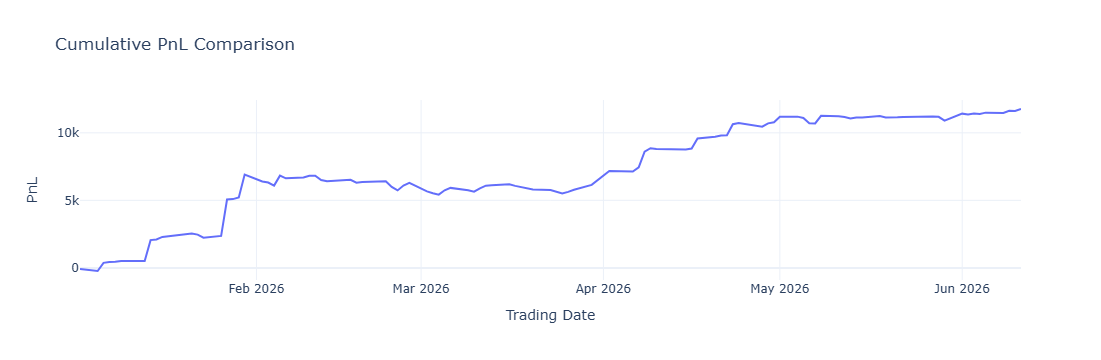

,PAAS-SLV
Total PnL,$11764
Total trades,587
Average trades per day,5.3
Number of trading dates,110
Average daily PnL,$107 (0.43%)
Average PnL per trade,$20 (0.5%)
Daily Sharpe,4.1
Max Drawdown,-1486
Notional,"10,000 / 10,000"


In [59]:
# Backtester
thres = 3
base_notional = 10000
total_slippage = 0.003
spreads = ['PAAS-SLV']
rt_col = 'fwd1m'
sd,ed = 20260101, df_data['Trading date'].max()
thres_max = 50 # Only for validation/testing
side = "All" # 'All', 'Long', 'Short'
#_______________________________________________________________
df_dict = {}
for spread in spreads:
    td_mask = (df_data['Trading date'].between(sd,ed , inclusive='both'))
    if side.lower() == 'all':
        side_mask = (df_data[f"{spread}_zscore"].abs().between(thres,thres_max))
    elif side.lower() == 'long':
        side_mask = (df_data[f"{spread}_zscore"].between(-thres_max, -thres))
    elif side.lower() == 'short':
        side_mask = (df_data[f"{spread}_zscore"].between(thres,thres_max))
        
    mask = (df_data['ind_nyse_rth']==True) & (df_data['ind_start_spread'] == 1) 
    df_group = df_data[mask & td_mask & side_mask].copy()
    z_abs = df_group[f"{spread}_zscore"].abs()
    df_group['Notional'] = np.where(z_abs > thres , base_notional ,np.nan)
    # df_group['Notional'] = np.where(z_abs > 3 , base_notional , np.where(z_abs>2.5, 0.8 * base_notional , np.where(z_abs > 2 , 0.65 * base_notional, np.nan)))
    
    z = df_group[f"{spread}_zscore"]
    df_group['ind_zscore2'] = np.where(z > thres, 1, np.where(z < -thres, -1, 0))
    df_group[f"{spread}_{rt_col}_adj"] = np.where(z > thres, -df_group[f"{spread}_{rt_col}"], np.where(z < -thres,  df_group[f"{spread}_{rt_col}"], np.nan))
    df_pregroup = df_group.copy()
    df_group2 = df_group.groupby('Trading date').agg({f"{spread}_{rt_col}_adj":['count', 'sum', 'mean'], 'Notional':['mean','max']}).reset_index()
    df_group = df_group.groupby(['Trading date','ind_zscore2']).agg({f"{spread}_{rt_col}_adj":['count', 'sum', 'mean'], 'Notional':['mean','max']}).reset_index()
    df_group.columns = [str(c1) if c0 == f"{spread}_{rt_col}_adj" else f"{c0}_{c1}" if c1 not in ("", None) else str(c0) for c0, c1 in df_group.columns]
    df_group2.columns = [str(c1) if c0 == f"{spread}_{rt_col}_adj" else f"{c0}_{c1}" if c1 not in ("", None) else str(c0) for c0, c1 in df_group2.columns]
    df_group2['Notional_sum'] = df_group2['count'] * df_group2['Notional_mean']
    df_group2['Netpnl'] = (df_group2['mean']-total_slippage) * df_group2['count'] * df_group2['Notional_mean']
    df_group2['Cumulative_netpnl'] = df_group2['Netpnl'].cumsum()
    globals()[f"df_pregroup_{spread.split('-')[0]}"] = df_pregroup.copy()
    globals()[f"df_group_{spread.split('-')[0]}"] = df_group.copy()
    globals()[f"df_group2_{spread.split('-')[0]}"] = df_group2.copy()
    df_dict[spread] = df_group2
fig, summary = pnl_summary_chart(df_dict, trading_date_col='Trading date', netpnl_col='Netpnl', cum_col='Cumulative_netpnl', count_col='count')
fig.show()
display(summary)

In [58]:
# convert_datetime_cols_to_string(df_data[df_data['Trading date']>20260301].reset_index(drop=True)).to_excel(rf"\\192.168.88.250\BigUSB\LAResearch\Silver stocks strategy\Validation\20260615.xlsx", index=False)

In [ ]:
# df_group_SLV[df_group_SLV['Trading date'] == 20260114]
# df_pregroup_SLV[df_pregroup_SLV['Trading date'] == 20260114][['Date_str', 'SLV', 'SI'] + [x for x in df_pregroup_SLV.columns if 'SLV-SI' in x]]

# Saving to Excel

In [ ]:
output_file = rf"{output_folder}{str(datetime.now())[:19].replace('-','').replace(':','-').replace(' ','_')}.xlsx"
pd.DataFrame().to_excel(output_file, sheet_name = 'Opengap strat')
with pd.ExcelWriter(output_file, mode = 'a', engine='openpyxl', if_sheet_exists = 'overlay') as writer:  
                convert_datetime_cols_to_string(df_all).to_excel(writer, index = False, sheet_name = 'Opengap strat')
                # convert_datetime_cols_to_string(df_data).to_excel(writer, index = False, sheet_name = 'df_data')
                df_appended.to_excel(writer, index = False, sheet_name = 'Spread results')
    

In [ ]:
# df_test = df_data.loc[(df_data['Trading date'].isin([20260209]) ) & (df_data['ind_nyse_rth'] == True)][['DT', 'PAAS']+[x for x in df_data.columns if 'PAAS' in x]]
# df_test.to_excel(rf"\\192.168.88.250\BigUSB\LAResearch\Silver stocks strategy\Validation\20260211_Test on 0209 data.xlsx", index=False)